In [1]:
import polars as pl
import numpy as np


In [2]:
df1 = pl.read_csv("dengue_features_train.csv")
df2 = pl.read_csv("dengue_labels_train.csv")

In [3]:
train_df = df1.join(
    df2,
    on=["city", "year", "weekofyear"],
    how="inner"
)
train_df.write_csv("train_data.csv")

In [4]:
train_data = pl.read_csv("train_data.csv")

In [5]:
train_data.head()

city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
str,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""sj""",1990,18,"""1990-04-30""",0.1226,0.103725,0.1984833,0.1776167,12.42,297.572857,297.742857,292.414286,299.8,295.9,32.0,73.365714,12.42,14.012857,2.628571,25.442857,6.9,29.4,20.0,16.0,4
"""sj""",1990,19,"""1990-05-07""",0.1699,0.142175,0.1623571,0.1554857,22.82,298.211429,298.442857,293.951429,300.9,296.4,17.94,77.368571,22.82,15.372857,2.371429,26.714286,6.371429,31.7,22.2,8.6,5
"""sj""",1990,20,"""1990-05-14""",0.03225,0.1729667,0.1572,0.1708429,34.54,298.781429,298.878571,295.434286,300.5,297.3,26.1,82.052857,34.54,16.848571,2.3,26.714286,6.485714,32.2,22.8,41.4,4
"""sj""",1990,21,"""1990-05-21""",0.1286333,0.2450667,0.2275571,0.2358857,15.36,298.987143,299.228571,295.31,301.4,297.0,13.9,80.337143,15.36,16.672857,2.428571,27.471429,6.771429,33.3,23.3,4.0,3
"""sj""",1990,22,"""1990-05-28""",0.1962,0.2622,0.2512,0.24734,7.52,299.518571,299.664286,295.821429,301.9,297.5,12.2,80.46,7.52,17.21,3.014286,28.942857,9.371429,35.0,23.9,5.8,6


In [6]:
train_data = train_data.drop("week_start_date")

In [7]:
sj_df = train_df.filter(pl.col("city") == "sj")
iq_df = train_df.filter(pl.col("city") == "iq")

In [8]:
sj_df = sj_df.drop("week_start_date")
iq_df = iq_df.drop("week_start_date")

In [9]:
sj_df.head()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""sj""",1990,18,0.1226,0.103725,0.1984833,0.1776167,12.42,297.572857,297.742857,292.414286,299.8,295.9,32.0,73.365714,12.42,14.012857,2.628571,25.442857,6.9,29.4,20.0,16.0,4
"""sj""",1990,19,0.1699,0.142175,0.1623571,0.1554857,22.82,298.211429,298.442857,293.951429,300.9,296.4,17.94,77.368571,22.82,15.372857,2.371429,26.714286,6.371429,31.7,22.2,8.6,5
"""sj""",1990,20,0.03225,0.1729667,0.1572,0.1708429,34.54,298.781429,298.878571,295.434286,300.5,297.3,26.1,82.052857,34.54,16.848571,2.3,26.714286,6.485714,32.2,22.8,41.4,4
"""sj""",1990,21,0.1286333,0.2450667,0.2275571,0.2358857,15.36,298.987143,299.228571,295.31,301.4,297.0,13.9,80.337143,15.36,16.672857,2.428571,27.471429,6.771429,33.3,23.3,4.0,3
"""sj""",1990,22,0.1962,0.2622,0.2512,0.24734,7.52,299.518571,299.664286,295.821429,301.9,297.5,12.2,80.46,7.52,17.21,3.014286,28.942857,9.371429,35.0,23.9,5.8,6


In [10]:
sj_df.null_count()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,191,49,19,19,9,6,6,6,6,6,6,6,9,6,6,6,6,6,6,6,0


In [11]:
iq_df.null_count()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,3,3,3,3,4,4,4,4,4,4,4,4,4,4,4,37,37,14,8,16,0


In [12]:
print("sj_df shape:", sj_df.shape)
print("iq_df shape:", iq_df.shape)

sj_df shape: (936, 24)
iq_df shape: (520, 24)


## SJ DF DATA ANALYISIS AND PREDICTION MODEL

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns


In [14]:
sj_df.head(10)

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""sj""",1990,18,0.1226,0.103725,0.1984833,0.1776167,12.42,297.572857,297.742857,292.414286,299.8,295.9,32.0,73.365714,12.42,14.012857,2.628571,25.442857,6.9,29.4,20.0,16.0,4
"""sj""",1990,19,0.1699,0.142175,0.1623571,0.1554857,22.82,298.211429,298.442857,293.951429,300.9,296.4,17.94,77.368571,22.82,15.372857,2.371429,26.714286,6.371429,31.7,22.2,8.6,5
"""sj""",1990,20,0.03225,0.1729667,0.1572,0.1708429,34.54,298.781429,298.878571,295.434286,300.5,297.3,26.1,82.052857,34.54,16.848571,2.3,26.714286,6.485714,32.2,22.8,41.4,4
"""sj""",1990,21,0.1286333,0.2450667,0.2275571,0.2358857,15.36,298.987143,299.228571,295.31,301.4,297.0,13.9,80.337143,15.36,16.672857,2.428571,27.471429,6.771429,33.3,23.3,4.0,3
"""sj""",1990,22,0.1962,0.2622,0.2512,0.24734,7.52,299.518571,299.664286,295.821429,301.9,297.5,12.2,80.46,7.52,17.21,3.014286,28.942857,9.371429,35.0,23.9,5.8,6
"""sj""",1990,23,null,0.17485,0.2543143,0.1817429,9.58,299.63,299.764286,295.851429,302.4,298.1,26.49,79.891429,9.58,17.212857,2.1,28.114286,6.942857,34.4,23.9,39.1,2
"""sj""",1990,24,0.1129,0.0928,0.2050714,0.2102714,3.48,299.207143,299.221429,295.865714,301.3,297.7,38.6,82.0,3.48,17.234286,2.042857,27.414286,6.771429,32.2,23.3,29.7,4
"""sj""",1990,25,0.0725,0.0725,0.1514714,0.1330286,151.12,299.591429,299.528571,296.531429,300.6,298.4,30.0,83.375714,151.12,17.977143,1.571429,28.371429,7.685714,33.9,22.8,21.1,5
"""sj""",1990,26,0.10245,0.146175,0.1255714,0.1236,19.32,299.578571,299.557143,296.378571,302.1,297.7,37.51,82.768571,19.32,17.79,1.885714,28.328571,7.385714,33.9,22.8,21.1,10


In [15]:
sj_df.select(["ndvi_ne", "ndvi_nw", "ndvi_se", "ndvi_sw"])

ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw
f64,f64,f64,f64
0.1226,0.103725,0.1984833,0.1776167
0.1699,0.142175,0.1623571,0.1554857
0.03225,0.1729667,0.1572,0.1708429
0.1286333,0.2450667,0.2275571,0.2358857
0.1962,0.2622,0.2512,0.24734
…,…,…,…
0.07785,-0.0399,0.3104714,0.2962429
-0.038,-0.016833,0.1193714,0.066386
-0.1552,-0.05275,0.1377571,0.1412143


In [16]:
ndvi_cols = ["ndvi_ne","ndvi_nw","ndvi_se","ndvi_sw"]

In [17]:
sj_df = sj_df.with_columns(
    pl.col(ndvi_cols)
      .fill_null(strategy="forward")
      .fill_null(strategy="backward")
)

In [18]:
rain_cols = [
    "reanalysis_air_temp_k","reanalysis_avg_temp_k",
    "reanalysis_dew_point_temp_k","reanalysis_max_air_temp_k",
    "reanalysis_min_air_temp_k","reanalysis_relative_humidity_percent",
    "reanalysis_specific_humidity_g_per_kg","reanalysis_tdtr_k",
    "station_avg_temp_c","station_diur_temp_rng_c",
    "station_max_temp_c","station_min_temp_c"
]
sj_df = sj_df.with_columns(
    pl.col(rain_cols)
      .fill_null(strategy="forward")
      .fill_null(strategy="backward")
)

In [19]:
cols = [
    "precipitation_amt_mm",
    "reanalysis_precip_amt_kg_per_m2",
    "reanalysis_sat_precip_amt_mm",
    "station_precip_mm",
]

sj_df = sj_df.with_columns(
    [pl.col(c).fill_null(strategy="forward") for c in cols]
)

In [20]:
sj_df.null_count()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [21]:
import polars.selectors as cs
corr_matrix = sj_df.select(cs.numeric()).corr() 
print(corr_matrix)


shape: (23, 23)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ year      ┆ weekofyea ┆ ndvi_ne   ┆ ndvi_nw   ┆ … ┆ station_m ┆ station_m ┆ station_p ┆ total_ca │
│ ---       ┆ r         ┆ ---       ┆ ---       ┆   ┆ ax_temp_c ┆ in_temp_c ┆ recip_mm  ┆ ses      │
│ f64       ┆ ---       ┆ f64       ┆ f64       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│           ┆ f64       ┆           ┆           ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1.0       ┆ -0.073143 ┆ -0.388985 ┆ -0.495028 ┆ … ┆ -0.169664 ┆ 0.000753  ┆ 0.084859  ┆ -0.21269 │
│ -0.073143 ┆ 1.0       ┆ -0.062458 ┆ -0.035011 ┆ … ┆ 0.32037   ┆ 0.518216  ┆ 0.214038  ┆ 0.287134 │
│ -0.388985 ┆ -0.062458 ┆ 1.0       ┆ 0.614698  ┆ … ┆ 0.10278   ┆ 0.002738  ┆ -0.08368  ┆ 0.004144 │
│ -0.495028 ┆ -0.035011 ┆ 0.614698  ┆ 1.0       ┆ … ┆ 0.136895  ┆ 0.017841 

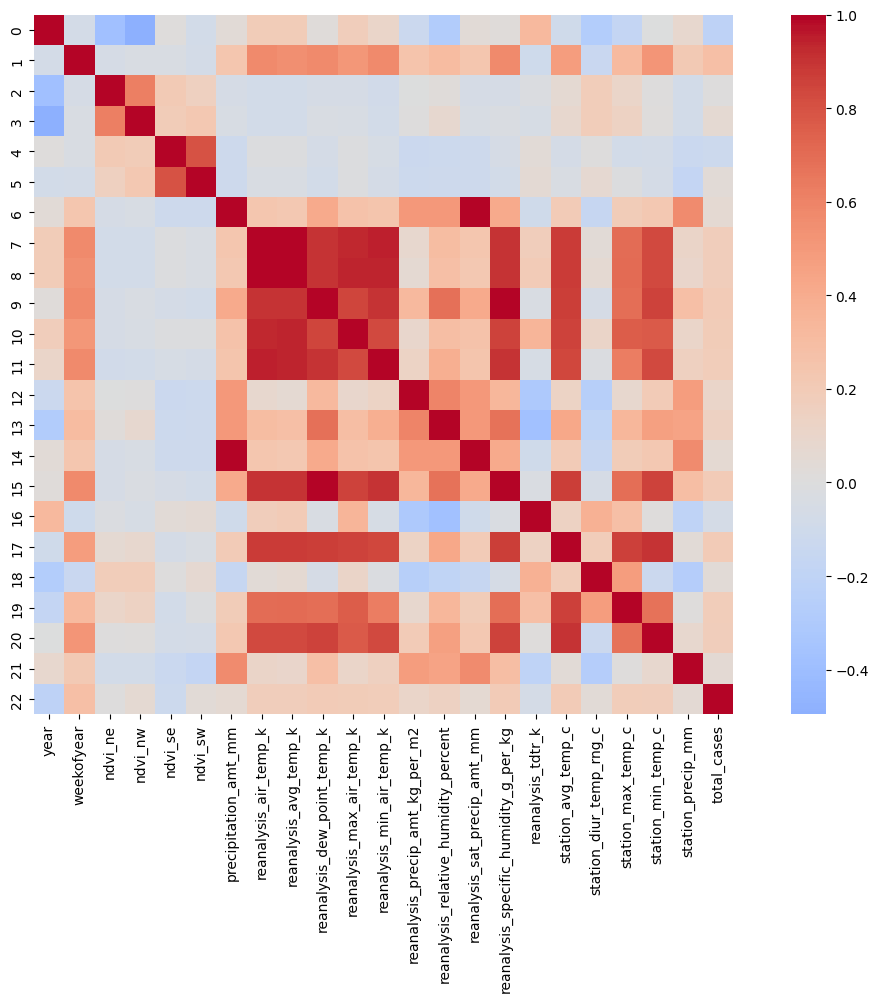

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix.to_pandas(),
    cmap="coolwarm",
    center=0,
    square=True
)
plt.tight_layout()
plt.show()


<Axes: >

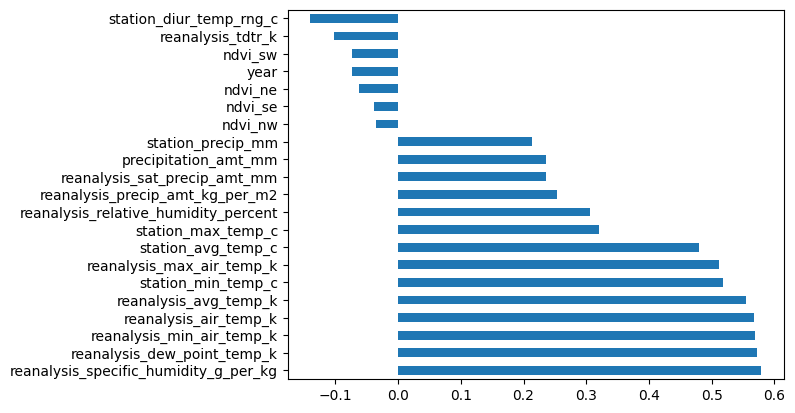

In [23]:
(
    corr_matrix
    .to_pandas()
    .iloc[1]
    .drop(["total_cases", "weekofyear"])
    .sort_values(ascending=False)
    .plot.barh()
)

In [29]:
sj_df.head()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""sj""",1990,18,0.1226,0.103725,0.1984833,0.1776167,12.42,297.572857,297.742857,292.414286,299.8,295.9,32.0,73.365714,12.42,14.012857,2.628571,25.442857,6.9,29.4,20.0,16.0,4
"""sj""",1990,19,0.1699,0.142175,0.1623571,0.1554857,22.82,298.211429,298.442857,293.951429,300.9,296.4,17.94,77.368571,22.82,15.372857,2.371429,26.714286,6.371429,31.7,22.2,8.6,5
"""sj""",1990,20,0.03225,0.1729667,0.1572,0.1708429,34.54,298.781429,298.878571,295.434286,300.5,297.3,26.1,82.052857,34.54,16.848571,2.3,26.714286,6.485714,32.2,22.8,41.4,4
"""sj""",1990,21,0.1286333,0.2450667,0.2275571,0.2358857,15.36,298.987143,299.228571,295.31,301.4,297.0,13.9,80.337143,15.36,16.672857,2.428571,27.471429,6.771429,33.3,23.3,4.0,3
"""sj""",1990,22,0.1962,0.2622,0.2512,0.24734,7.52,299.518571,299.664286,295.821429,301.9,297.5,12.2,80.46,7.52,17.21,3.014286,28.942857,9.371429,35.0,23.9,5.8,6


In [35]:
cols_sj = [
    "reanalysis_specific_humidity_g_per_kg",
    "reanalysis_dew_point_temp_k",
    "reanalysis_min_temp_k",
    "reanalysis_avg_temp_k",
    "reanalysis_air_temp_k",
    "reanalysis_relative_humidity_percent",
    "precipitation_amt_mm",
    "station_avg_temp_c",
    "station_min_temp_c",
    "station_max_temp_c"
]


In [38]:
X = sj_df.select(cols_sj)
y = sj_df["total_cases"]

In [39]:
X

reanalysis_specific_humidity_g_per_kg,reanalysis_dew_point_temp_k,reanalysis_avg_temp_k,reanalysis_air_temp_k,reanalysis_relative_humidity_percent,precipitation_amt_mm,station_avg_temp_c,station_min_temp_c,station_max_temp_c
f64,f64,f64,f64,f64,f64,f64,f64,f64
14.012857,292.414286,297.742857,297.572857,73.365714,12.42,25.442857,20.0,29.4
15.372857,293.951429,298.442857,298.211429,77.368571,22.82,26.714286,22.2,31.7
16.848571,295.434286,298.878571,298.781429,82.052857,34.54,26.714286,22.8,32.2
16.672857,295.31,299.228571,298.987143,80.337143,15.36,27.471429,23.3,33.3
17.21,295.821429,299.664286,299.518571,80.46,7.52,28.942857,23.9,35.0
…,…,…,…,…,…,…,…,…
13.644286,292.095714,296.957143,296.958571,74.247143,27.19,25.042857,21.1,30.0
14.662857,293.235714,298.228571,298.081429,74.6,3.82,26.242857,22.2,30.6
14.184286,292.732857,297.564286,297.46,75.027143,16.96,25.0,21.7,29.4


In [40]:
y

total_cases
i64
4
5
4
3
6
…
4
3
1


In [41]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [42]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y,test_size=0.2,shuffle=False)

In [43]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
preds = lr.predict(X_test)

In [47]:
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(y_test, preds))
print("RMSE:", rmse)


RMSE: 29.503934016236464


In [48]:
import pandas as pd

coefficients = pd.Series(
    lr.coef_,
    index=cols
).sort_values()

print(coefficients)


reanalysis_dew_point_temp_k             -153.279601
reanalysis_avg_temp_k                    -58.164853
station_avg_temp_c                       -10.847248
precipitation_amt_mm                      -4.212159
station_min_temp_c                         3.424071
station_max_temp_c                        10.737407
reanalysis_relative_humidity_percent      45.213388
reanalysis_specific_humidity_g_per_kg     66.575115
reanalysis_air_temp_k                    131.020286
dtype: float64


In [49]:
iq_df = iq_df.with_columns(
    pl.col(ndvi_cols)
      .fill_null(strategy="forward")
      .fill_null(strategy="backward")
)

In [50]:
iq_df = iq_df.with_columns(
    pl.col(rain_cols)
      .fill_null(strategy="forward")
      .fill_null(strategy="backward")
)

In [51]:
iq_df = iq_df.with_columns(
    [pl.col(c).fill_null(strategy="forward") for c in cols]
)

In [52]:
iq_df.null_count()

city,year,weekofyear,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,4,0,4,0,0,0,0,0,0,16,0


In [53]:
corr_matrix_iq = iq_df.select(cs.numeric()).corr()
print(corr_matrix_iq)

shape: (23, 23)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ year      ┆ weekofyea ┆ ndvi_ne   ┆ ndvi_nw   ┆ … ┆ station_m ┆ station_m ┆ station_p ┆ total_ca │
│ ---       ┆ r         ┆ ---       ┆ ---       ┆   ┆ ax_temp_c ┆ in_temp_c ┆ recip_mm  ┆ ses      │
│ f64       ┆ ---       ┆ f64       ┆ f64       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│           ┆ f64       ┆           ┆           ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1.0       ┆ -0.136842 ┆ -0.061312 ┆ 0.033645  ┆ … ┆ 0.014077  ┆ 0.127615  ┆ NaN       ┆ 0.179451 │
│ -0.136842 ┆ 1.0       ┆ 0.257832  ┆ 0.226371  ┆ … ┆ 0.189582  ┆ -0.093604 ┆ NaN       ┆ -0.01185 │
│ -0.061312 ┆ 0.257832  ┆ 1.0       ┆ 0.764985  ┆ … ┆ 0.142054  ┆ -0.007827 ┆ NaN       ┆ 0.01974  │
│ 0.033645  ┆ 0.226371  ┆ 0.764985  ┆ 1.0       ┆ … ┆ 0.149415  ┆ -0.090059

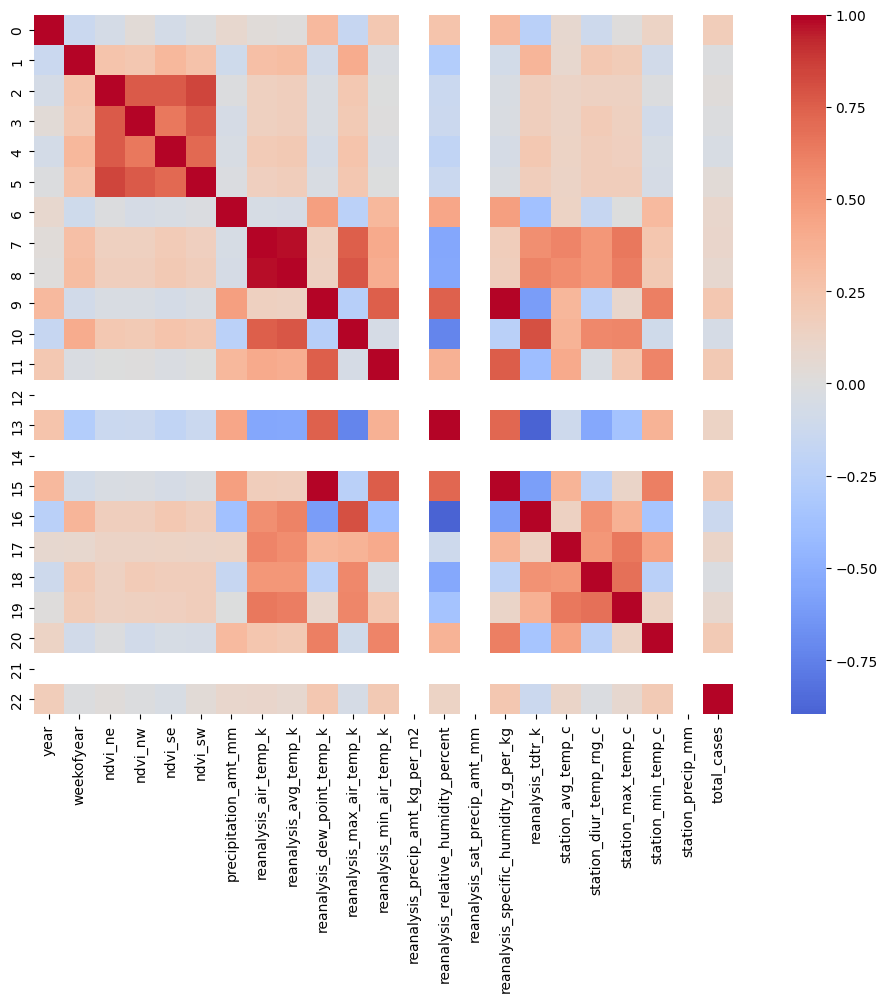

In [54]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix_iq.to_pandas(),
    cmap="coolwarm",
    center=0,
    square=True
)
plt.tight_layout()
plt.show()

<Axes: >

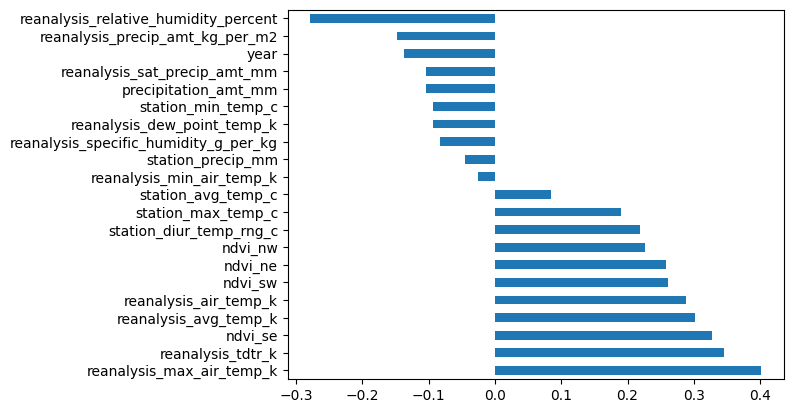

In [ ]:
(
    corr_matrix_iq
    .to_pandas()
    .iloc[1]
    .drop(["total_cases", "weekofyear"])
    .sort_values(ascending=False)
    .plot.barh()
)

In [ ]:
cols_iq = [
"reanalysis_max_air_temp_k",
"reanalysis_tdtr_k",
"ndvi_se",
"reanalysis_avg_temp_k",
"reanalysis_air_temp_k",
"ndvi_ne",
"ndvi_nw",
"ndvi_sw",
"station_max_temp_c",
"station_diur_temp_rng_c",
"station_avg_temp_c"
]

In [ ]:
X = iq_df.select(cols_iq)
y = iq_df["total_cases"]


In [ ]:
scaler = StandardScaler()
X_scaled_iq = scaler.fit_transform(X)

NameError: name 'StandardScaler' is not defined